# 01 - Data loading, cleaning and EDA

This notebook is a thin, readable wrapper around `src/`. Every function used here is the
same one `run_pipeline.py` calls, so the notebook cannot drift from the pipeline.

Run it from the `notebooks/` folder (the `sys.path` line adds the project root).

In [1]:
import sys
sys.path.insert(0, "..")

import pandas as pd

from src.config import BUILDING_LABELS, BUILDINGS, SITE_ID
from src.data_loader import build_panel
from src.features import build_features

panel = build_panel(list(BUILDINGS), SITE_ID)
print(f"raw panel: {panel.shape[0]:,} rows, {panel['building_id'].nunique()} buildings")
print(panel.head(3).to_string())

raw panel: 70,176 rows, 4 buildings
            timestamp          building_id  electricity  airTemperature  cloudCoverage  dewTemperature  precipDepth1HR  windSpeed      sqm primaryspaceusage sub_primaryspaceusage
0 2016-01-01 00:00:00  Fox_education_Andre       463.80             7.2            0.0            -5.6             0.0        0.0  17044.0         Education    College Laboratory
1 2016-01-01 01:00:00  Fox_education_Andre       440.84             7.2            0.0            -6.7             0.0        1.5  17044.0         Education    College Laboratory
2 2016-01-01 02:00:00  Fox_education_Andre       425.25             6.1            0.0            -5.0             0.0        0.0  17044.0         Education    College Laboratory


In [2]:
# Cleaning: full hourly grid, negative values -> missing, short gaps interpolated.
features, quality = build_features(panel)
quality

,building_id,hours_total,hours_raw_present,hours_imputed,hours_still_missing,pct_complete_after_repair,zero_hours
0,Fox_education_Andre,17544,17543,1,0,100.000,0
1,Fox_education_Claire,17544,17542,2,0,100.000,0
2,Fox_education_Elvira,17544,17522,21,1,99.994,0
3,Fox_education_Kendrick,17544,17540,4,0,100.000,0


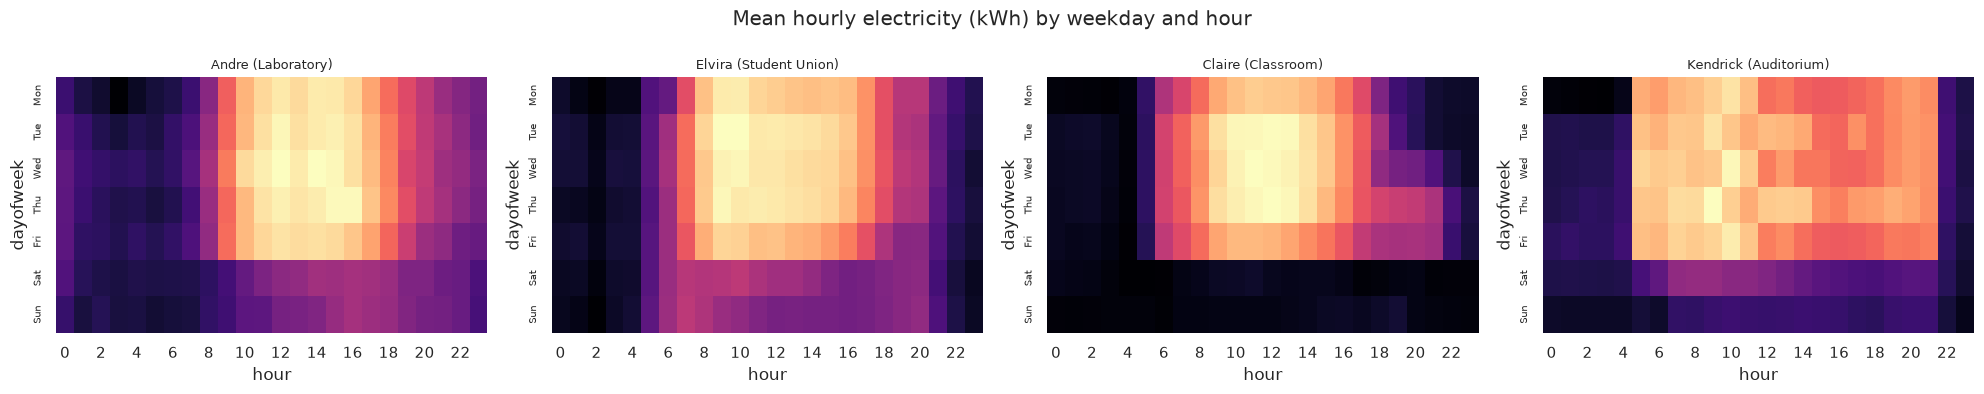

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
features["building_label"] = features["building_id"].map(BUILDING_LABELS)

fig, axes = plt.subplots(1, 4, figsize=(20, 4))
for ax, (building_id, label) in zip(axes, BUILDING_LABELS.items()):
    subset = features[features["building_id"] == building_id]
    pivot = subset.pivot_table(index="dayofweek", columns="hour", values="electricity", aggfunc="mean")
    sns.heatmap(pivot, ax=ax, cmap="magma", cbar=False)
    ax.set_title(label, fontsize=9)
    ax.set_yticklabels(["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"], fontsize=7)
    ax.set_xlabel("hour")
plt.suptitle("Mean hourly electricity (kWh) by weekday and hour")
plt.tight_layout()
plt.show()

In [4]:
# Weekday vs weekend shape, plus how much of the daily mean is baseload.
summary = (
    features.dropna(subset=["electricity"])
    .groupby(["building_label", "is_weekend"])["electricity"]
    .agg(mean_kwh="mean", p05=lambda s: s.quantile(0.05), max_kwh="max")
    .round(2)
)
summary

mean_kwh     p05  max_kwh
building_label         is_weekend                           
Andre (Laboratory)     0             464.60  386.03   640.88
                       1             429.72  380.66   550.32
Claire (Classroom)     0              67.88   31.39   113.95
                       1              43.70   28.11    99.31
Elvira (Student Union) 0             197.24  111.64   426.87
                       1             169.40  108.93   406.41
Kendrick (Auditorium)  0              13.98    4.29    62.84
                       1               8.66    3.37    61.60

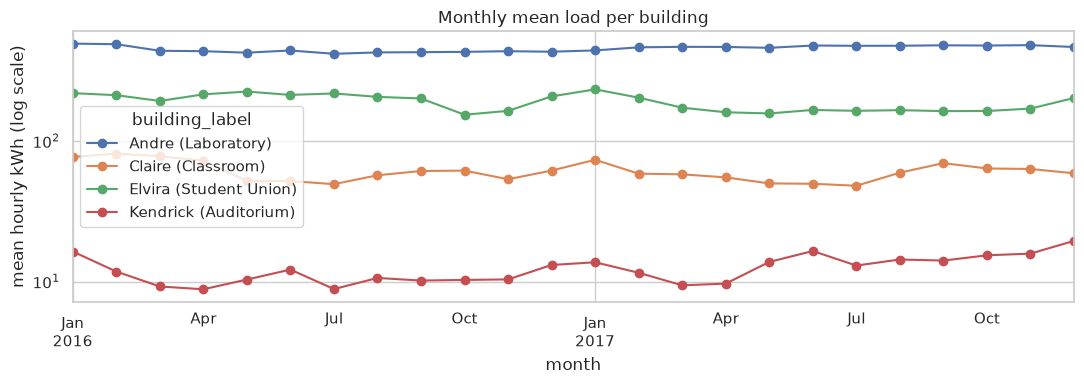

In [5]:
# Seasonality: monthly mean load, log scale because the buildings differ ~37x.
monthly = (
    features.dropna(subset=["electricity"])
    .assign(month=lambda d: d["timestamp"].dt.to_period("M").dt.to_timestamp())
    .groupby(["month", "building_label"])["electricity"].mean()
    .unstack()
)
monthly.plot(figsize=(11, 4), marker="o", logy=True)
plt.ylabel("mean hourly kWh (log scale)")
plt.title("Monthly mean load per building")
plt.tight_layout()
plt.show()